In [19]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Visualização
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# Estatística
from scipy import stats

path = "data/heart_disease_uci.csv"
# Carregar dados
df = pd.read_csv(path)

print(f"Shape dos dados: {df.shape}")
print(f"\nPrimeiras linhas do dataset:")
df.head(10)

Shape dos dados: (920, 16)

Primeiras linhas do dataset:


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0
5,6,56,Male,Cleveland,atypical angina,120.0,236.0,False,normal,178.0,False,0.8,upsloping,0.0,normal,0
6,7,62,Female,Cleveland,asymptomatic,140.0,268.0,False,lv hypertrophy,160.0,False,3.6,downsloping,2.0,normal,3
7,8,57,Female,Cleveland,asymptomatic,120.0,354.0,False,normal,163.0,True,0.6,upsloping,0.0,normal,0
8,9,63,Male,Cleveland,asymptomatic,130.0,254.0,False,lv hypertrophy,147.0,False,1.4,flat,1.0,reversable defect,2
9,10,53,Male,Cleveland,asymptomatic,140.0,203.0,True,lv hypertrophy,155.0,True,3.1,downsloping,0.0,reversable defect,1


In [20]:
print("=== INFORMAÇÕES GERAIS DO DATASET ===\n")
print(df.info())

print("\n=== ESTATÍSTICAS DESCRITIVAS ===\n")
df.describe()

=== INFORMAÇÕES GERAIS DO DATASET ===

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 156.4+ KB
None

=== ESTATÍSTICAS DESCRITIVAS ===



,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


=== ANÁLISE DE MISSING VALUES ===

            Coluna  Missing_Count  Missing_Percentage
ca              ca            611               66.41
thal          thal            486               52.83
slope        slope            309               33.59
fbs            fbs             90                9.78
oldpeak    oldpeak             62                6.74
trestbps  trestbps             59                6.41
exang        exang             55                5.98
thalch      thalch             55                5.98
chol          chol             30                3.26
restecg    restecg              2                0.22


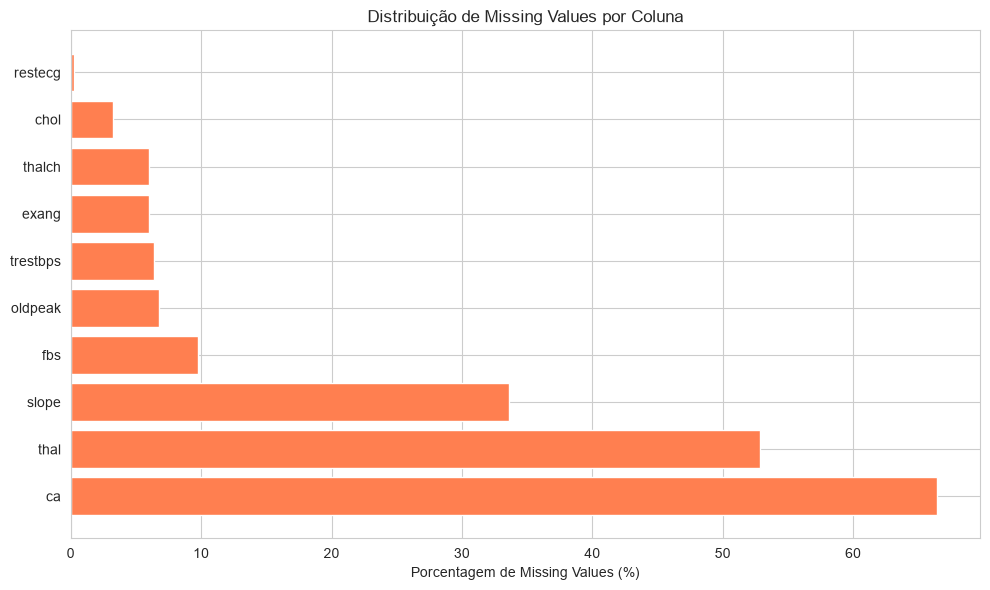

In [21]:
print("=== ANÁLISE DE MISSING VALUES ===\n")
missing_values = pd.DataFrame({
    'Coluna': df.columns,
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().sum() / len(df) * 100).round(2)
})
missing_values = missing_values[missing_values['Missing_Count'] > 0].sort_values(
    by="Missing_Percentage", ascending=False
)

if len(missing_values) > 0:
    print(missing_values)

    plt.figure(figsize=(10, 6))
    plt.barh(missing_values['Coluna'], missing_values['Missing_Percentage'], color='coral')
    plt.xlabel('Porcentagem de Missing Values (%)')
    plt.title('Distribuição de Missing Values por Coluna')
    plt.tight_layout()
    plt.show()
else:
    print("Nenhum missing value detectado!")

=== DISTRIBUIÇÃO DA VARIÁVEL TARGET ===

Contagem:
target
1    509
0    411
Name: count, dtype: int64

Percentual:
Com doença (1): 55.33%
Sem doença (0): 44.67%


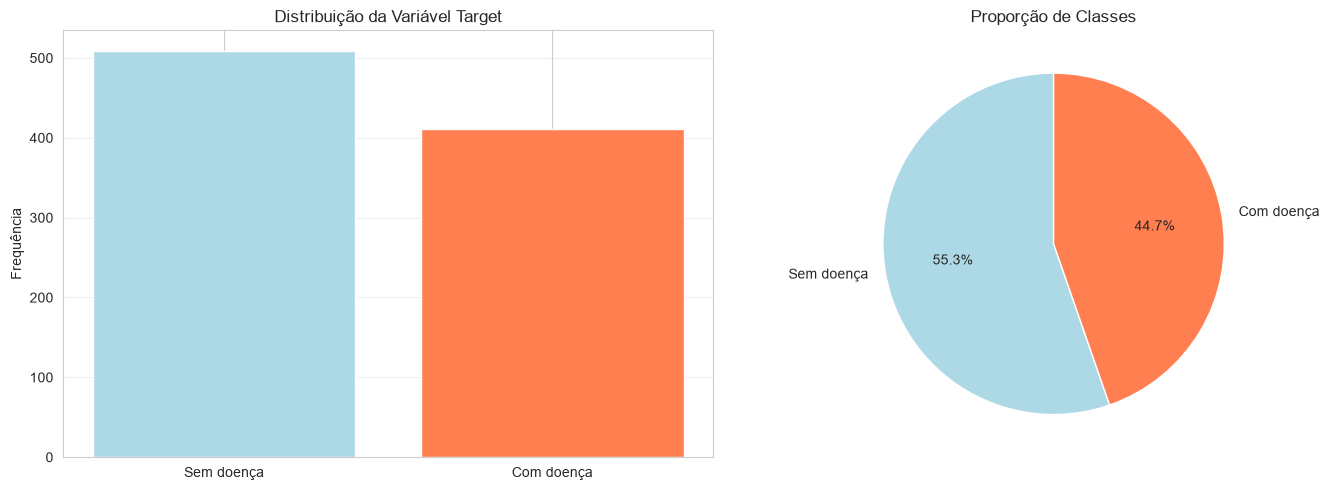


Ratio de balanceamento: 0.81
✅Dataset razoavelmente balanceado.


In [22]:
df.rename(columns={'num': 'target'}, inplace=True)
df['target'] = (df['target'] > 0).astype(int)
print("=== DISTRIBUIÇÃO DA VARIÁVEL TARGET ===\n")
target_counts = df['target'].value_counts()
target_percentages = df['target'].value_counts(normalize=True) * 100
print("Contagem:")
print(target_counts)
print("\nPercentual:")
for idx, pct in target_percentages.items():
    label = "Sem doença" if idx == 0 else "Com doença"
    print(f"{label} ({idx}): {pct:.2f}%")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(['Sem doença', 'Com doença'], target_counts.values, color=['lightblue', 'coral'])
axes[0].set_ylabel('Frequência')
axes[0].set_title('Distribuição da Variável Target')
axes[0].grid(axis='y', alpha=0.3)

axes[1].pie(target_counts.values, labels=['Sem doença', 'Com doença'], autopct='%1.1f%%', colors=['lightblue', 'coral'], startangle=90)
axes[1].set_title('Proporção de Classes')
plt.tight_layout()
plt.show()

ratio = target_counts.min() / target_counts.max()
print(f"\nRatio de balanceamento: {ratio:.2f}")
if ratio < 0.5:
    print("⚠️Dataset desbalaceado! Considere usar técnicas como SMOTE ou class_weight.")
else:
    print("✅Dataset razoavelmente balanceado.")

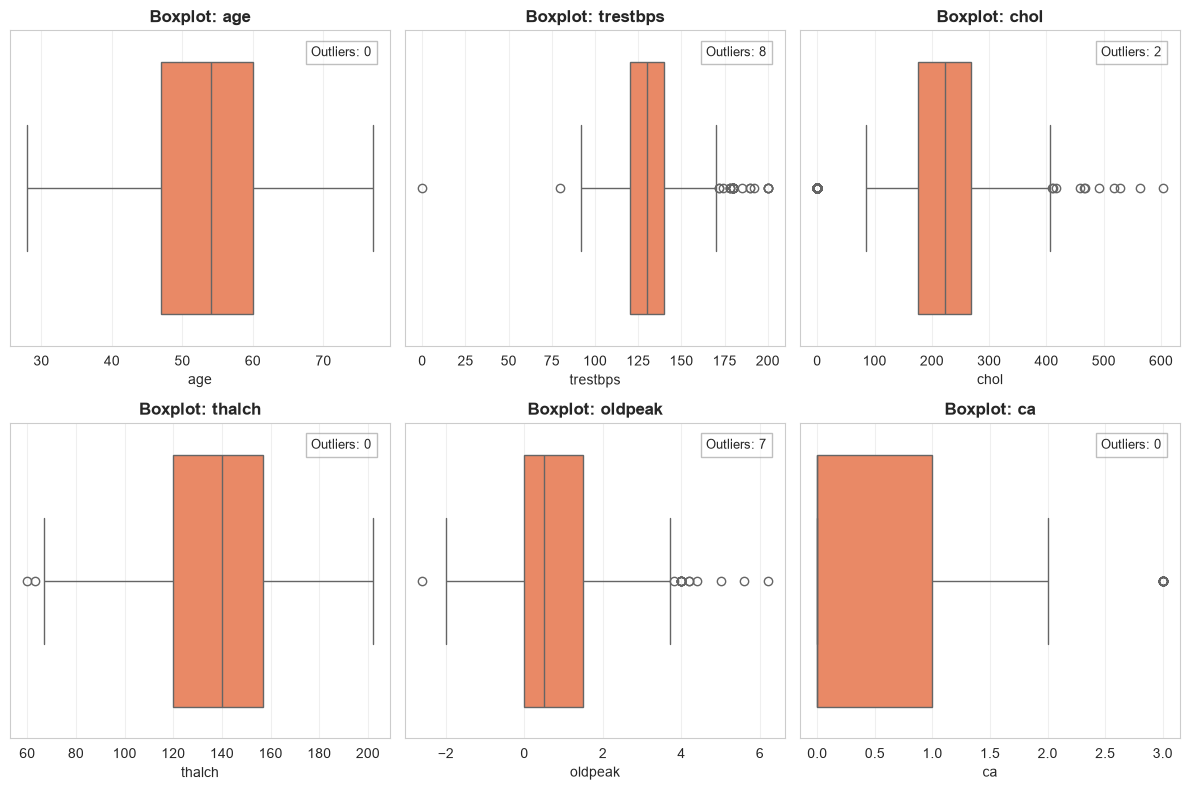

In [23]:
numeric_cols = df.select_dtypes(include=[np.number]).columns
numeric_cols = numeric_cols.drop(['id', 'target'])
n = len(numeric_cols)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 4 * nrows))
axes = axes.ravel()
for idx, col in enumerate(numeric_cols):
    sns.boxplot(x=df[col], ax=axes[idx], color='coral')
    axes[idx].set_title(f'Boxplot: {col}', fontweight='bold')
    axes[idx].set_xlabel(col)
    axes[idx].grid(axis='x', alpha=0.3)
    col_zscore = np.abs(stats.zscore(df[col].dropna()))
    outlier_count = (col_zscore > 3).sum()
    axes[idx].text(0.95, 0.95, f'Outliers: {outlier_count}',
                   transform=axes[idx].transAxes, fontsize=9,
                   verticalalignment='top', horizontalalignment='right',
                   bbox=dict(facecolor='white', alpha=0.5, edgecolor='gray'))
for ax in axes[n:]:
    fig.delaxes(ax)
plt.tight_layout()
plt.show()

In [24]:
print("=== TRATAMENTO DE MISSING VALUES ===\n")
df_clean = df.copy()
num_missing = ['trestbps', 'chol', 'thalch', 'oldpeak', 'ca']
for col in num_missing:
    if col in df_clean.columns:
        median = df_clean[col].median()
        df_clean[col] = df_clean[col].fillna(median)
        print(f"{col}: imputado com mediana ({median:.2f})")

for col in cat_missing:
    if col in df_clean.columns:
        mode = df_clean[col].mode()[0]
        df_clean[col] = df_clean[col].fillna(mode)
        print(f"{col}: imputado com moda ('{mode}')")
print("\n✅ Tratamento de missing values concluído!")
print(f"Shape após imputação: {df_clean.shape}")
print("Valores ausentes restantes por coluna:")
print(df_clean.isnull().sum())

=== TRATAMENTO DE MISSING VALUES ===

trestbps: imputado com mediana (130.00)
chol: imputado com mediana (223.00)
thalch: imputado com mediana (140.00)
oldpeak: imputado com mediana (0.50)
ca: imputado com mediana (0.00)
thal: imputado com moda ('normal')
slope: imputado com moda ('flat')
fbs: imputado com moda ('False')
exang: imputado com moda ('False')
restecg: imputado com moda ('normal')

✅ Tratamento de missing values concluído!
Shape após imputação: (920, 16)
Valores ausentes restantes por coluna:
id          0
age         0
sex         0
dataset     0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalch      0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


In [25]:
df_clean.drop(columns=['dataset'], inplace=True)
categorical_cols = ['sex', 'cp', 'restecg', 'slope', 'thal']
df_encoded = pd.get_dummies(df_clean, columns=categorical_cols, drop_first=True)
print(f"Shape após one-hot encoding: {df_encoded.shape}")
df_encoded.head()

Shape após one-hot encoding: (920, 20)


,id,age,trestbps,chol,fbs,thalch,exang,oldpeak,ca,target,sex_Male,cp_atypical angina,cp_non-anginal,cp_typical angina,restecg_normal,restecg_st-t abnormality,slope_flat,slope_upsloping,thal_normal,thal_reversable defect
0,1,63,145.0,233.0,True,150.0,False,2.3,0.0,0,True,False,False,True,False,False,False,False,False,False
1,2,67,160.0,286.0,False,108.0,True,1.5,3.0,1,True,False,False,False,False,False,True,False,True,False
2,3,67,120.0,229.0,False,129.0,True,2.6,2.0,1,True,False,False,False,False,False,True,False,False,True
3,4,37,130.0,250.0,False,187.0,False,3.5,0.0,0,True,False,True,False,True,False,False,False,True,False
4,5,41,130.0,204.0,False,172.0,False,1.4,0.0,0,False,True,False,False,False,False,False,True,True,False


In [26]:
from sklearn.model_selection import train_test_split
X = df_encoded.drop(columns=["id", "target"])
y = df_encoded["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [27]:
import mlflow
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
mlflow.set_experiment("heart_disease_classification")
with mlflow.start_run(run_name="logistic_regression_baseline"):
   model = LogisticRegression(random_state=42)
   model.fit(X_train, y_train)
   y_pred_train = model.predict(X_train)
   y_pred_test = model.predict(X_test)
   train_accuracy = accuracy_score(y_train, y_pred_train)
   test_accuracy = accuracy_score(y_test, y_pred_test)
   test_f1 = f1_score(y_test, y_pred_test)
   test_precision = precision_score(y_test, y_pred_test)
   test_recall = recall_score(y_test, y_pred_test)
   mlflow.log_metric("train_accuracy", train_accuracy)
   mlflow.log_metric("test_accuracy", test_accuracy)
   mlflow.log_metric("test_f1_score", test_f1)
   mlflow.log_metric("test_precision", test_precision)
   mlflow.log_metric("test_recall", test_recall)
   overfitting = train_accuracy - test_accuracy
   print(f"=== LOGISTIC REGRESSION ===")
   print(f"Train Accuracy: {train_accuracy:.4f}")
   print(f"Test Accuracy:  {test_accuracy:.4f}")
   print(f"Test F1 Score:  {test_f1:.4f}")
   print(f"Test Precision: {test_precision:.4f}")
   print(f"Test Recall:    {test_recall:.4f}")
   print(f"Overfitting:    {overfitting:.4f}")

=== LOGISTIC REGRESSION ===
Train Accuracy: 0.8207
Test Accuracy:  0.8043
Test F1 Score:  0.8302
Test Precision: 0.8544
Test Recall:    0.8073
Overfitting:    0.0163
